In [1]:
from pathlib import Path

import pandas as pd
from PIL import Image
import torch
from matplotlib import pyplot as plt

from common import METRICS, CLASSES_FRAMEWORK
from model import Detector

In [2]:
classes = {
    "attacks": CLASSES_FRAMEWORK,
    "metrics": METRICS,
}

In [3]:
samples = pd.read_csv("samples/quantile_idxs.csv")
samples = samples.sort_values(["attack", "metric"]).reset_index(drop=True)
quantile_columns = [m for m in classes["metrics"] if m != "clean"]

In [4]:
images = []
for _, r in samples.iterrows():
    filename = (
        f"{r['dataset']}-original-{r['file_name']}"
        if r['attack'] == "clean" else
        f"{r['dataset']}_{r['preset']}_{r['attack']}_{r['metric']}_{r['file_name']}"
    )
    images.append(Image.open(Path("samples/images") / filename).convert("RGB"))

In [5]:
label_maps = [
    {0: "clean", 1: "Attacked"},
    {v: k for k, v in classes["attacks"].items()},
    {v: k for k, v in classes["metrics"].items()},
]

In [6]:
names = {
    "clean": "Clean",
    "ifgsm": "I-FGSM",
    "uap": "Optimised-UAP",
    "clip-iqa-plus": "CLIP-IQA+",
    "fpr": "FPR",
    "koncept": "KonCept",
    "linearity": "Linearity",
    "maniqa": "MANIQA",
    "meta-iqa": "MetaIQA",
    "paq2piq": "PaQ-2-PiQ",
    "spaq": "SPAQ",
    "topiq-nr": "TOPIQ-NR",
}

def get_name(label, names=names):
    return names.get(label, label)

In [7]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

In [8]:
model_path = "weights.ckpt"
detector = Detector.load_from_checkpoint(
    model_path, map_location="cpu", pretrained=False
).to(device).eval()

In [9]:
preds, probas = [], []
with torch.inference_mode():
    for i, image in enumerate(images):
        x, _ = detector.transform_val(image)
        x = x.unsqueeze(0).to(device)
        q = torch.tensor(
            samples.loc[i, quantile_columns].tolist(),
            dtype=torch.float32, device=device,
        ).unsqueeze(0) / 100.0
        probabilities = [head.softmax(dim=1)[0].cpu() for head in detector(x, q)]
        preds.append([int(p.argmax()) for p in probabilities])
        probas.append([float(p.max()) for p in probabilities])

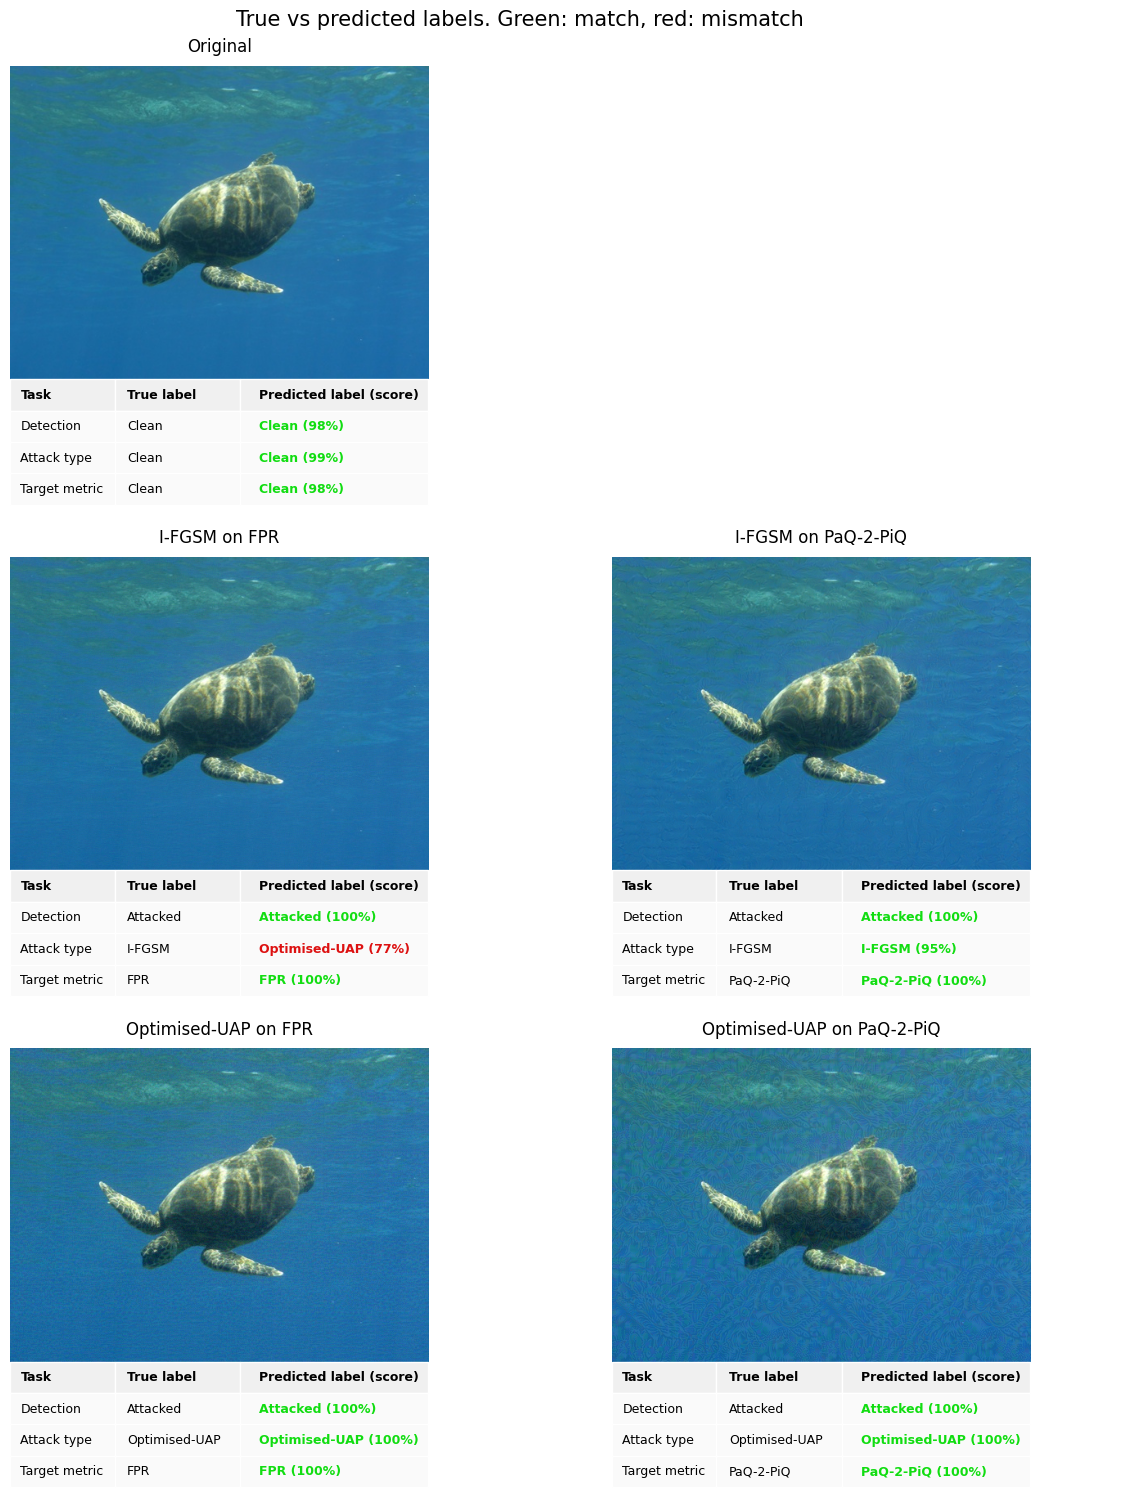

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(12, 15), layout="constrained")

for ax in axes.flat:
    ax.axis("off")

image_axes = [
    axes[0, 0], axes[1, 0], axes[1, 1], axes[2, 0], axes[2, 1]
]

for i, (ax, image) in enumerate(zip(image_axes, images)):
    r = samples.iloc[i]

    ax.imshow(image)
    ax.set_title(
        "Original" if r.attack == "clean" else f"{get_name(r.attack)} on {get_name(r.metric)}",
        fontsize=12, pad=10
    )

    label_true = [int(r.attack != "clean"), classes["attacks"][r.attack], classes["metrics"][r.metric]]
    rows = [
        [
            task,
            get_name(label_maps[j][label_true[j]]),
            f"{get_name(label_maps[j][preds[i][j]])} ({probas[i][j]:.0%})"
        ]
        for j, task in enumerate(["Detection", "Attack type", "Target metric"])
    ]
    table = ax.table(
        cellText=rows, colLabels=["Task", "True label", "Predicted label (score)"],
        cellLoc="left", colLoc="left", colWidths=[0.25, 0.3, 0.45],
        bbox=[0, -0.4, 1, 0.4],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("white")
        cell.set_facecolor("#f0f0f0" if row == 0 else "#fafafa")
        if row == 0:
            cell.get_text().set_weight("bold")
        elif col == 2:
            match = preds[i][row - 1] == label_true[row - 1]
            cell.get_text().set_color("#11dd11" if match else "#dd1111")
            cell.get_text().set_weight("bold")

fig.suptitle("True vs predicted labels. Green: match, red: mismatch", fontsize=15)
plt.show()